# Onboarding checklist A/B test

**Question.** Does the new guided onboarding checklist get more new workspaces to their first report
(activation), and does that carry through to trials and revenue?

**Design.** From 2 Feb to 26 Apr 2026, every new workspace owner was randomly assigned 50/50 to the
`classic` flow (control) or the `guided_checklist` flow (treatment). The test is
`onboarding_checklist_v1`.

| | Metric | Definition (see `docs/metrics_spec.md`) |
|---|---|---|
| Primary | Activation | First report created within 7 days of signup |
| Secondary | Trial start | Trial started within 30 days, after activating |
| Guardrail | Paid conversion | First subscription within 45 days |
| Guardrail | Onboarding completion | Onboarding completed within 1 day |

Decision rule, set before reading results: ship if activation improves at the 5% significance level and
paid conversion doesn't fall.

The data comes from the warehouse (`core.dim_account` and `intermediate.int_account_funnel`), so these
numbers match the dashboard exactly.

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import (confint_proportions_2indep, proportion_confint,
                                          proportion_effectsize, proportions_ztest)

from analysis.warehouse import query

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
CONTROL, TREATMENT = "#8a8f98", "#2f6fdb"

In [2]:
df = query('''
    select a.account_id, a.segment, a.signup_channel, a.onboarding_experiment_variant as variant,
           f.is_onboarded, f.is_activated, f.is_trial_started, f.is_paid, f.is_mature
    from core.dim_account as a
    inner join intermediate.int_account_funnel as f on a.account_id = f.account_id
    where a.onboarding_experiment_variant is not null
''')
print(f"{len(df):,} workspaces in the test; all cohorts mature: {df['is_mature'].all()}")
df.groupby("variant").size()

1,518 workspaces in the test; all cohorts mature: True


variant
control      785
treatment    733
dtype: int64

## 1. Sanity check: was the split really 50/50?

A sample ratio mismatch (SRM) would mean the randomisation or the logging is broken, and the results
can't be trusted however good they look.

In [3]:
counts = df["variant"].value_counts().sort_index()
chi2, p_srm = stats.chisquare(counts)
print(f"control {counts['control']}, treatment {counts['treatment']}: chi-square p = {p_srm:.2f}")
print("No sample ratio mismatch." if p_srm > 0.01 else "Sample ratio mismatch: investigate before reading results.")

control 785, treatment 733: chi-square p = 0.18
No sample ratio mismatch.


## 2. Results

Two-proportion z-tests, with Newcombe confidence intervals for the difference in rates.

In [4]:
METRICS = {"is_onboarded": "Onboarding completion", "is_activated": "Activation (primary)",
           "is_trial_started": "Trial start", "is_paid": "Paid conversion"}

def compare(data, metric):
    t = data.loc[data["variant"] == "treatment", metric]
    c = data.loc[data["variant"] == "control", metric]
    _, p = proportions_ztest([t.sum(), c.sum()], [len(t), len(c)])
    lo, hi = confint_proportions_2indep(t.sum(), len(t), c.sum(), len(c), method="newcomb")
    return {"control": c.mean(), "treatment": t.mean(), "diff_pts": 100 * (t.mean() - c.mean()),
            "ci_low_pts": 100 * lo, "ci_high_pts": 100 * hi,
            "relative_lift": t.mean() / c.mean() - 1, "p_value": p}

results = pd.DataFrame({label: compare(df, m) for m, label in METRICS.items()}).T
results.style.format({"control": "{:.1%}", "treatment": "{:.1%}", "diff_pts": "{:+.1f}",
                      "ci_low_pts": "{:+.1f}", "ci_high_pts": "{:+.1f}", "relative_lift": "{:+.0%}",
                      "p_value": "{:.4f}"})

,control,treatment,diff_pts,ci_low_pts,ci_high_pts,relative_lift,p_value
Onboarding completion,72.4%,75.2%,+2.8,-1.6,+7.2,+4%,0.2133
Activation (primary),41.0%,50.9%,+9.9,+4.9,+14.8,+24%,0.0001
Trial start,23.7%,27.8%,+4.1,-0.3,+8.5,+17%,0.0653
Paid conversion,10.4%,11.3%,+0.9,-2.3,+4.0,+8%,0.5831


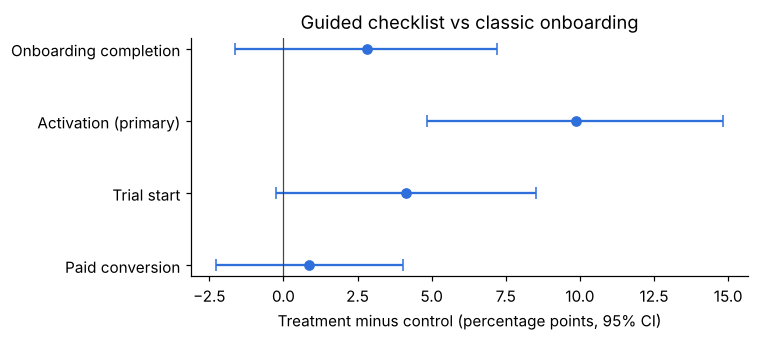

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.2))
y = np.arange(len(results))[::-1]
ax.errorbar(results["diff_pts"], y,
            xerr=[results["diff_pts"] - results["ci_low_pts"], results["ci_high_pts"] - results["diff_pts"]],
            fmt="o", color=TREATMENT, capsize=4)
ax.axvline(0, color="#444", lw=0.8)
ax.set_yticks(y, results.index)
ax.set_xlabel("Treatment minus control (percentage points, 95% CI)")
ax.set_title("Guided checklist vs classic onboarding")
plt.tight_layout()

**Reading the results.**

- **Activation rose by about 10 points**, from 41% to 51% (a relative lift of about 24%). The interval
  is well clear of zero and p < 0.001. The primary metric passes.
- **Onboarding completion and trial starts** moved up too, but their intervals include zero.
- **Paid conversion is flat** (about +1 point, not significant). That's not evidence of no effect: the
  next section shows the test was never big enough to detect a realistic change in paid conversion.

## 3. Was the test big enough?

Power for detecting an absolute lift in activation, given the sample we actually had (about 750 per arm)
and a 41% baseline. Then, how many workspaces we'd need to detect a 1-point change in paid conversion.

To detect +1 point in paid conversion (from 10.4%) we'd need about 15,294 workspaces per arm, roughly 20x this test.


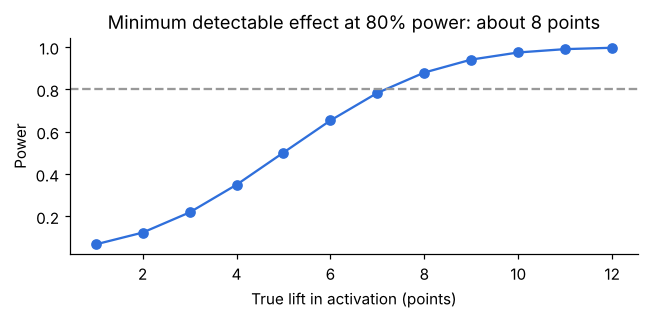

In [6]:
n_c, n_t = counts["control"], counts["treatment"]
base_act = results.loc["Activation (primary)", "control"]
power = NormalIndPower()

lifts = np.arange(0.01, 0.13, 0.01)
curve = [power.power(proportion_effectsize(base_act + d, base_act), nobs1=n_c, ratio=n_t / n_c, alpha=0.05)
         for d in lifts]
mde = next(d for d, pw in zip(lifts, curve) if pw >= 0.8)

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(100 * lifts, curve, marker="o", color=TREATMENT)
ax.axhline(0.8, ls="--", color="#999")
ax.set_xlabel("True lift in activation (points)")
ax.set_ylabel("Power")
ax.set_title(f"Minimum detectable effect at 80% power: about {100 * mde:.0f} points")
plt.tight_layout()

base_paid = results.loc["Paid conversion", "control"]
needed = power.solve_power(proportion_effectsize(base_paid + 0.01, base_paid), power=0.8, alpha=0.05)
print(f"To detect +1 point in paid conversion (from {base_paid:.1%}) we'd need about {needed:,.0f} "
      f"workspaces per arm, roughly {needed / (len(df) / 2):.0f}x this test.")

## 4. Does the effect hold across segments?

A check for consistency, not a fishing trip: with four segments, some differences will look large by
chance. Intervals are Wilson 95% intervals per cell.

variant,control,treatment
segment,,
Enterprise,81,62
Mid-Market,182,155
SMB,509,499


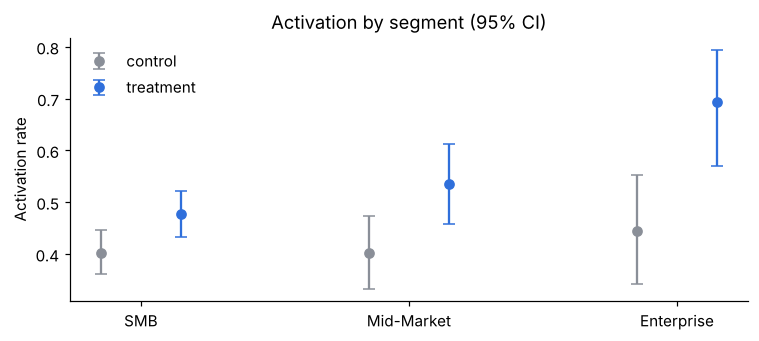

In [7]:
seg = (df[df["segment"] != "Unknown"]
       .groupby(["segment", "variant"])["is_activated"].agg(["sum", "size"]).reset_index())
seg["rate"] = seg["sum"] / seg["size"]
seg[["lo", "hi"]] = seg.apply(lambda r: pd.Series(proportion_confint(r["sum"], r["size"], method="wilson")), axis=1)

fig, ax = plt.subplots(figsize=(7, 3.2))
order = ["SMB", "Mid-Market", "Enterprise"]
for i, (variant, color) in enumerate([("control", CONTROL), ("treatment", TREATMENT)]):
    s = seg[seg["variant"] == variant].set_index("segment").loc[order]
    x = np.arange(len(order)) + (i - 0.5) * 0.3
    ax.errorbar(x, s["rate"], yerr=[s["rate"] - s["lo"], s["hi"] - s["rate"]], fmt="o", color=color,
                capsize=4, label=variant)
ax.set_xticks(np.arange(len(order)), order)
ax.set_ylabel("Activation rate")
ax.legend(frameon=False)
ax.set_title("Activation by segment (95% CI)")
plt.tight_layout()
seg.pivot(index="segment", columns="variant", values="size")

The treatment is ahead in every segment. The gap looks largest for Enterprise, but that segment has
only about 140 workspaces in the test, so its interval is wide. The honest conclusion is "consistent
direction everywhere", not "it works best for Enterprise".

## 5. Did the gain hold after rollout?

The checklist became the default for every signup from 11 May 2026. A before/after comparison is
confounded by seasonality and channel mix, so it supports the experiment rather than replacing it.

Six months before the test: 40.7%. After rollout: 45.3%.


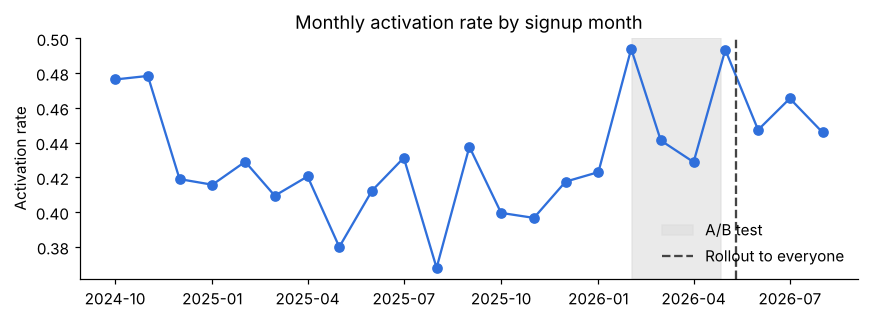

In [8]:
monthly = query('''
    select a.signup_date, f.is_activated
    from core.dim_account as a
    inner join intermediate.int_account_funnel as f on a.account_id = f.account_id
    where not a.is_internal and f.is_mature
''')
monthly["month"] = pd.to_datetime(monthly["signup_date"]).dt.to_period("M").dt.to_timestamp()
rate = monthly.groupby("month")["is_activated"].mean()

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(rate.index, rate.values, marker="o", color=TREATMENT)
ax.axvspan(pd.Timestamp("2026-02-02"), pd.Timestamp("2026-04-27"), color="#ddd", alpha=0.6, label="A/B test")
ax.axvline(pd.Timestamp("2026-05-11"), ls="--", color="#444", label="Rollout to everyone")
ax.set_ylabel("Activation rate")
ax.legend(frameon=False, loc="lower right")
ax.set_title("Monthly activation rate by signup month")
plt.tight_layout()

before = rate[rate.index < "2026-02-01"].tail(6).mean()
after = rate[rate.index >= "2026-06-01"].mean()
print(f"Six months before the test: {before:.1%}. After rollout: {after:.1%}.")

Activation has run about 4 to 5 points higher since rollout. That is smaller than the 10 points the test
measured, but still inside the test's confidence interval (roughly +5 to +15 points). Two reasons to
expect this:

- **Winner's curse.** We act on experiments that came out well, so the measured lift of a shipped
  change tends to overstate the true one. The low end of the interval is the safer planning number.
- **Mix shift.** Post-rollout signups come from a different blend of channels and seasons than the
  test's February to April cohorts.

## Recommendation

**Keep the guided checklist** (it is already rolled out). It raised activation by about 10 points, from
41% to 51%. The result is highly significant and consistent across segments, and activation has stayed
4 to 5 points above its pre-test level since rollout. For forecasting, plan on a gain of about 5 points,
the low end of the test's interval, rather than the headline 10.

**Don't claim a revenue effect yet.** Paid conversion didn't move measurably, and this test could only
have detected a much bigger change than is realistic. Track paid conversion for post-rollout cohorts as
they mature, and if revenue impact matters for the next decision, size the test for that metric up front.

**Caveats.** Results are per workspace owner. Activation is a leading indicator, and its link to
long-term retention is examined in the retention notebook.